In [14]:
%pip install scikit-image

In [15]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from torchvision.ops import MLP
import torch.nn as nn
from torch.utils.data import DataLoader, random_split, TensorDataset
import numpy as np
import torch.optim as optim
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)
import scipy.linalg
import pandas as pd
import torch.nn as nn
import torch.optim as optim
import time

In [16]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [17]:
def measure_latency(model, input_shape, is_gan=False):
    model.eval()
    dummy_input = torch.randn(input_shape).to(device)
    start_time = time.time()
    with torch.no_grad():
        if is_gan:
            model(dummy_input) # Generator takes noise
        else:
            model(dummy_input) # AE takes images
    latency_ms = (time.time() - start_time) * 1000
    return latency_ms

def plot_training_graph(losses, title):
    plt.figure(figsize=(8, 4))
    plt.plot(losses, label='Training Loss')
    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

In [18]:
import torch
import torchvision
from torch.utils.data import DataLoader, TensorDataset, random_split

train_raw = torchvision.datasets.FashionMNIST(root="./data", train=True, download=True)
test_raw = torchvision.datasets.FashionMNIST(root="./data", train=False, download=True)

X_all = torch.cat([train_raw.data, test_raw.data], dim=0).float().view(-1, 784) / 255.0
y_all = torch.cat([train_raw.targets, test_raw.targets], dim=0)

total_size = len(X_all)
train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size

generator = torch.Generator().manual_seed(42)
train_split, val_split, test_split = random_split(
    range(total_size), [train_size, val_size, test_size], generator=generator
)

x_train, y_train = X_all[train_split.indices], y_all[train_split.indices]
x_val, y_val = X_all[val_split.indices], y_all[val_split.indices]
x_test, y_test = X_all[test_split.indices], y_all[test_split.indices]

mean, std = x_train.mean(), x_train.std()
x_train = (x_train - mean) / std
x_val = (x_val - mean) / std
x_test = (x_test - mean) / std

print(f"Train: {x_train.shape} | Val: {x_val.shape} | Test: {x_test.shape}")

batch_size = 128

train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(x_val, y_val), batch_size=batch_size, shuffle=False)
test_loader = DataLoader(TensorDataset(x_test, y_test), batch_size=batch_size, shuffle=False)

Train: torch.Size([56000, 784]) | Val: torch.Size([7000, 784]) | Test: torch.Size([7000, 784])


In [19]:
class VanillaAutoencoder(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=256, latent_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

autoencoder = VanillaAutoencoder(input_dim=784, hidden_dim=256, latent_dim=64).to(device)
criterion_ae = nn.MSELoss()
optimizer_ae = optim.Adam(autoencoder.parameters(), lr=1e-3)

ae_train_loader = DataLoader(TensorDataset(x_train), batch_size=128, shuffle=True)

ae_losses = []
ae_epochs = 30
start_train_ae = time.time()

In [20]:
autoencoder.train()
for epoch in range(ae_epochs):
    total_loss = 0.0
    for batch in ae_train_loader:
        x = batch[0].to(device)
        optimizer_ae.zero_grad()
        reconstructed = autoencoder(x)
        loss = criterion_ae(reconstructed, x)
        loss.backward()
        optimizer_ae.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(ae_train_loader)
    ae_losses.append(avg_loss)
    if (epoch + 1) % 5 == 0 or epoch == 0:
         print(f"Vanilla AE Epoch [{epoch+1}/{ae_epochs}] Loss: {avg_loss:.6f}")

time_per_epoch_ae = (time.time() - start_train_ae) / ae_epochs
latency_ae = measure_latency(autoencoder, (64, 784))

print(f"Vanilla AE Training Complete. Avg Time/Epoch: {time_per_epoch_ae:.2f}s")

Vanilla AE Epoch [1/30] Loss: 0.566467
Vanilla AE Epoch [5/30] Loss: 0.484724
Vanilla AE Epoch [10/30] Loss: 0.474433
Vanilla AE Epoch [15/30] Loss: 0.470688
Vanilla AE Epoch [20/30] Loss: 0.468747
Vanilla AE Epoch [25/30] Loss: 0.467720
Vanilla AE Epoch [30/30] Loss: 0.466807
Vanilla AE Training Complete. Avg Time/Epoch: 1.13s


In [21]:
autoencoder.eval()
with torch.no_grad():
    ae_recon = autoencoder(x_test.to(device)).cpu().numpy()

original_np = x_test.numpy()
ae_mse_scores = []
ae_psnr_scores = []

for i in range(len(original_np)):
    orig_img = original_np[i].reshape(28, 28)
    recon_img = ae_recon[i].reshape(28, 28)
    mse = np.mean((orig_img - recon_img) ** 2)
    psnr = peak_signal_noise_ratio(orig_img, recon_img, data_range=1.0)
    ae_mse_scores.append(mse)
    ae_psnr_scores.append(psnr)

ae_metrics = {
    "MSE": np.mean(ae_mse_scores),
    "PSNR": np.mean(ae_psnr_scores)
}

print("Vanilla AE Metrics:", ae_metrics)

Vanilla AE Metrics: {'MSE': np.float32(0.4686815), 'PSNR': np.float64(3.4032991863774384)}


# Variational Auto Encoder

In [22]:


class FashionMNISTVAE(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=256, latent_dim=64):
        super().__init__()
        # Encoder
        self.encoder_fc = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU()
        )
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid()
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        h = self.encoder_fc(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        z = self.reparameterize(mu, logvar)
        reconstructed = self.decoder(z)
        return reconstructed, mu, logvar

def vae_loss_function(recon_x, x, mu, logvar):
    # Reconstruction loss (using MSE, summed over all dimensions)
    recon_loss = nn.functional.mse_loss(recon_x, x, reduction='sum')
    # Kullback-Leibler divergence loss
    kld_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + kld_loss

In [23]:
# Initialize the VAE
vae_model = FashionMNISTVAE(input_dim=784, hidden_dim=256, latent_dim=64).to(device)
vae_optimizer = optim.Adam(vae_model.parameters(), lr=1e-3)

# Loader using original flattened images
vae_train_loader = DataLoader(TensorDataset(x_train), batch_size=128, shuffle=True)

vae_epochs = 30
vae_model.train()

for epoch in range(vae_epochs):
    total_loss = 0.0
    for batch in vae_train_loader:
        x = batch[0].to(device)

        vae_optimizer.zero_grad()
        reconstructed, mu, logvar = vae_model(x)
        loss = vae_loss_function(reconstructed, x, mu, logvar)
        loss.backward()
        vae_optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(vae_train_loader.dataset)
    if (epoch + 1) % 5 == 0 or epoch == 0:
         print(f"VAE Epoch [{epoch+1}/{vae_epochs}] Loss: {avg_loss:.4f}")

VAE Epoch [1/30] Loss: 502.2663
VAE Epoch [5/30] Loss: 429.5117
VAE Epoch [10/30] Loss: 418.1715
VAE Epoch [15/30] Loss: 415.1364
VAE Epoch [20/30] Loss: 413.7010
VAE Epoch [25/30] Loss: 412.6412
VAE Epoch [30/30] Loss: 411.9987


In [24]:
import scipy.linalg
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import inception_v3, Inception_V3_Weights

def calculate_fid(act1, act2):
    # Calculate mean and covariance statistics of activations
    mu1, sigma1 = act1.mean(axis=0), np.cov(act1, rowvar=False)
    mu2, sigma2 = act2.mean(axis=0), np.cov(act2, rowvar=False)

    # Sum quadratic difference between means
    ssdiff = np.sum((mu1 - mu2)**2.0)

    # Calculate square root of product of covariances
    covmean, _ = scipy.linalg.sqrtm(sigma1.dot(sigma2), disp=False)

    # Check and correct imaginary numbers from numerical precision
    if np.iscomplexobj(covmean):
        covmean = covmean.real

    # Calculate score
    fid = ssdiff + np.trace(sigma1 + sigma2 - 2.0 * covmean)
    return fid

# Load pre-trained InceptionV3 model for FID calculation
inception_model = inception_v3(weights=Inception_V3_Weights.DEFAULT, transform_input=False).to(device)
inception_model.fc = nn.Identity() # Remove the final classification layer to get raw features
inception_model.eval()

# Helper to extract activations using InceptionV3
def get_latent_activations(images_tensor, batch_size=32):
    activations = []
    with torch.no_grad():
        # Process in batches to avoid running out of RAM with 299x299 images
        for i in range(0, len(images_tensor), batch_size):
            batch = images_tensor[i:i+batch_size]

            if len(batch.shape) == 2:
                batch = batch.view(-1, 1, 28, 28)

            # Convert grayscale (1 channel) to RGB (3 channels)
            batch = batch.repeat(1, 3, 1, 1)

            # Resize 28x28 to 299x299 as expected by InceptionV3
            batch = F.interpolate(batch, size=(299, 299), mode='bilinear', align_corners=False)
            batch = batch.to(device)

            act = inception_model(batch).cpu().numpy()
            activations.append(act)

    return np.concatenate(activations, axis=0)

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 215MB/s]


/tmp/ipykernel_475/2798934102.py:17: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = scipy.linalg.sqrtm(sigma1.dot(sigma2), disp=False)


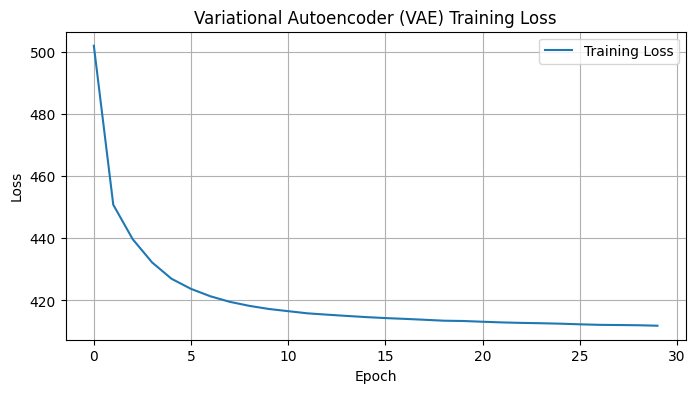

VAE - Time/Epoch: 1.50s
VAE - Latency (batch 64): 0.51ms
VAE - FID Score: 87.0444


In [25]:
import scipy.linalg
import time

# Re-training VAE to track time and losses
vae_model = FashionMNISTVAE(input_dim=784, hidden_dim=256, latent_dim=64).to(device)
vae_optimizer = optim.Adam(vae_model.parameters(), lr=1e-3)
vae_train_loader = DataLoader(TensorDataset(x_train), batch_size=128, shuffle=True)

vae_epochs = 30
vae_losses = []
start_train_vae = time.time()

vae_model.train()
for epoch in range(vae_epochs):
    total_loss = 0.0
    for batch in vae_train_loader:
        x = batch[0].to(device)
        vae_optimizer.zero_grad()
        reconstructed, mu, logvar = vae_model(x)
        loss = vae_loss_function(reconstructed, x, mu, logvar)
        loss.backward()
        vae_optimizer.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(vae_train_loader.dataset)
    vae_losses.append(avg_loss)

time_per_epoch_vae = (time.time() - start_train_vae) / vae_epochs
latency_vae = measure_latency(vae_model, (64, 784))

# Recalculate VAE Metrics including FID
vae_model.eval()
with torch.no_grad():
    vae_recon, _, _ = vae_model(x_test.to(device))
vae_acts = get_latent_activations(vae_recon)

# Calculate real acts
real_acts = get_latent_activations(x_test)

vae_fid = calculate_fid(real_acts, vae_acts)

plot_training_graph(vae_losses, "Variational Autoencoder (VAE) Training Loss")
print(f"VAE - Time/Epoch: {time_per_epoch_vae:.2f}s")
print(f"VAE - Latency (batch 64): {latency_vae:.2f}ms")
print(f"VAE - FID Score: {vae_fid:.4f}")

In [26]:
def evaluate_vae(model, x_data):
    model.eval()
    with torch.no_grad():
        # Standard VAE forward returns: reconstruction, mu, logvar
        reconstructed, _, _ = model(x_data.to(device))
        reconstructed = reconstructed.cpu().numpy()

    original = x_data.numpy()

    mse_scores = []
    psnr_scores = []

    for i in range(len(original)):
        original_img = original[i].reshape(28, 28)
        reconstructed_img = reconstructed[i].reshape(28, 28)

        mse = np.mean((original_img - reconstructed_img) ** 2)
        psnr = peak_signal_noise_ratio(original_img, reconstructed_img, data_range=1.0)

        mse_scores.append(mse)
        psnr_scores.append(psnr)

    return {
        "MSE": np.mean(mse_scores),
        "PSNR": np.mean(psnr_scores)
    }

vae_metrics = evaluate_vae(vae_model, x_test)
print("VAE Metrics:", vae_metrics)

VAE Metrics: {'MSE': np.float32(0.5038604), 'PSNR': np.float64(3.0819307186765332)}


In [27]:
comparison_data = {
    "Vanilla Autoencoder": {
        "MSE": ae_metrics["MSE"],
        "PSNR": ae_metrics["PSNR"]
    },
    "Variational Autoencoder (VAE)": {
        "MSE": vae_metrics["MSE"],
        "PSNR": vae_metrics["PSNR"]
    }
}

comparison_df = pd.DataFrame(comparison_data).T
display(comparison_df)

,MSE,PSNR
Vanilla Autoencoder,0.468682,3.403299
Variational Autoencoder (VAE),0.503860,3.081931


In [29]:
# Real Activations
real_acts = get_latent_activations(x_test)

# Vanilla AE Activations
autoencoder.eval()
with torch.no_grad():
    ae_recon = autoencoder(x_test.to(device))
ae_acts = get_latent_activations(ae_recon)

# VAE Activations
vae_model.eval()
with torch.no_grad():
    vae_recon, _, _ = vae_model(x_test.to(device))
vae_acts = get_latent_activations(vae_recon)

# Calculate FID for each model
ae_fid = calculate_fid(real_acts, ae_acts)
vae_fid = calculate_fid(real_acts, vae_acts)

print(f"Vanilla AE FID: {ae_fid:.4f}")
print(f"VAE FID: {vae_fid:.4f}")

/tmp/ipykernel_475/2798934102.py:17: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = scipy.linalg.sqrtm(sigma1.dot(sigma2), disp=False)


Vanilla AE FID: 73.0754
VAE FID: 87.4641


In [30]:
# Update comparison table with FID scores included
comparison_data_with_fid = {
    "Vanilla Autoencoder": {
        "MSE": ae_metrics["MSE"],
        "PSNR": ae_metrics["PSNR"],
        "FID Score": ae_fid
    },
    "Variational Autoencoder (VAE)": {
        "MSE": vae_metrics["MSE"],
        "PSNR": vae_metrics["PSNR"],
        "FID Score": vae_fid
    }
}

comparison_with_fid_df = pd.DataFrame(comparison_data_with_fid).T
display(comparison_with_fid_df)

,MSE,PSNR,FID Score
Vanilla Autoencoder,0.468682,3.403299,73.075443
Variational Autoencoder (VAE),0.503860,3.081931,87.464150


## Advanced Generative Models & Unified Metric Tracking

#### 1. Sparse Autoencoder (Latent 64)

Epoch [1/30] Loss: 0.908374
Epoch [5/30] Loss: 0.851658
Epoch [10/30] Loss: 0.851521
Epoch [15/30] Loss: 0.851499
Epoch [20/30] Loss: 0.851447
Epoch [25/30] Loss: 0.851473
Epoch [30/30] Loss: 0.851440
----------------------------------------
Sparse AE - Time/Epoch: 1.33s
Sparse AE - Latency (batch 64): 0.33ms
Sparse AE - Test MSE: 0.853749
Sparse AE - Test PSNR: 0.85 dB
----------------------------------------


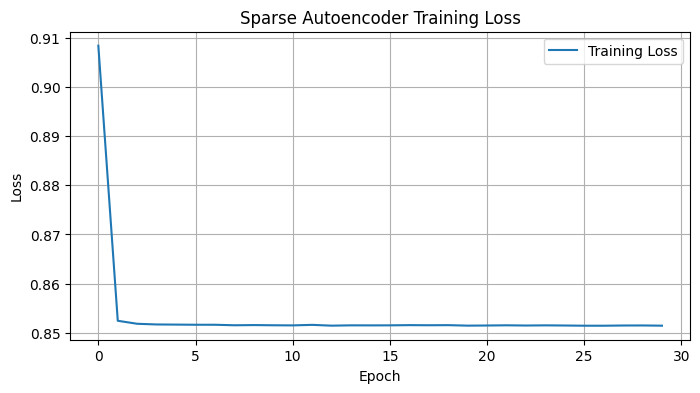

In [31]:
class SparseAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 64), nn.ReLU() # ReLU enforces non-negative sparse activations
        )
        self.decoder = nn.Sequential(
            nn.Linear(64, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid()
        )
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

sparse_ae = SparseAutoencoder().to(device)
optimizer_sae = torch.optim.Adam(sparse_ae.parameters(), lr=1e-3)
criterion_sae = nn.MSELoss()

# Training Loop (Batch Size 128)
sae_loader = DataLoader(TensorDataset(x_train), batch_size=128, shuffle=True)
sae_losses = []
epochs_sae = 30
start_train = time.time()

sparse_ae.train()
for epoch in range(epochs_sae):
    epoch_loss = 0
    for batch in sae_loader:
        x = batch[0].to(device)
        optimizer_sae.zero_grad()
        recon, z = sparse_ae(x)

        # L1 penalty for sparsity
        l1_penalty = 1e-3 * torch.sum(torch.abs(z))
        loss = criterion_sae(recon, x) + l1_penalty

        loss.backward()
        optimizer_sae.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(sae_loader)
    sae_losses.append(avg_loss)
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{epochs_sae}] Loss: {avg_loss:.6f}")

time_per_epoch_sae = (time.time() - start_train) / epochs_sae
latency_sae = measure_latency(sparse_ae, (64, 784))

# Evaluation for MSE and PSNR
sparse_ae.eval()
with torch.no_grad():
    sae_recons, _ = sparse_ae(x_test.to(device))
    sae_recons = sae_recons.cpu().numpy()

sae_mse_scores = []
sae_psnr_scores = []
original_np = x_test.numpy()

for i in range(len(original_np)):
    orig_img = original_np[i].reshape(28, 28)
    recon_img = sae_recons[i].reshape(28, 28)
    sae_mse_scores.append(np.mean((orig_img - recon_img)**2))
    sae_psnr_scores.append(peak_signal_noise_ratio(orig_img, recon_img, data_range=1.0))

sae_test_mse = np.mean(sae_mse_scores)
sae_test_psnr = np.mean(sae_psnr_scores)

print("-" * 40)
print(f"Sparse AE - Time/Epoch: {time_per_epoch_sae:.2f}s")
print(f"Sparse AE - Latency (batch 64): {latency_sae:.2f}ms")
print(f"Sparse AE - Test MSE: {sae_test_mse:.6f}")
print(f"Sparse AE - Test PSNR: {sae_test_psnr:.2f} dB")
print("-" * 40)

plot_training_graph(sae_losses, "Sparse Autoencoder Training Loss")

#### 2. GAN (Latent 100)

Epoch [1/30] Generator Loss: 5.597955
Epoch [5/30] Generator Loss: 11.876571
Epoch [10/30] Generator Loss: 44.653846
Epoch [15/30] Generator Loss: 44.653555
Epoch [20/30] Generator Loss: 44.635382
Epoch [25/30] Generator Loss: 44.596712
Epoch [30/30] Generator Loss: 44.462709


/tmp/ipykernel_475/2798934102.py:17: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = scipy.linalg.sqrtm(sigma1.dot(sigma2), disp=False)
/tmp/ipykernel_475/2798934102.py:17: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean, _ = scipy.linalg.sqrtm(sigma1.dot(sigma2), disp=False)


----------------------------------------
GAN - Time/Epoch: 2.62s
GAN - Latency (batch 64): 0.24ms
GAN - FID Score: 532.0857
----------------------------------------


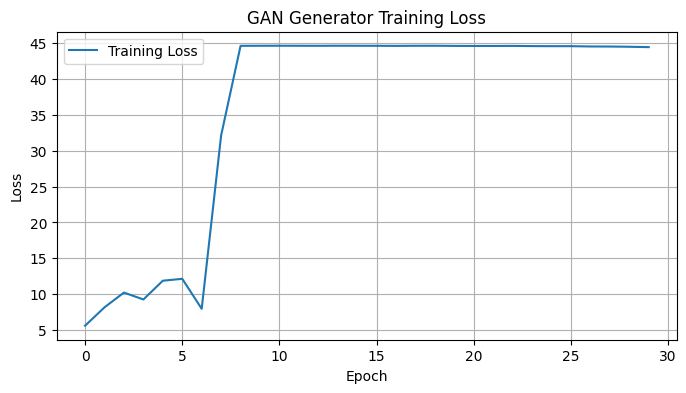

In [32]:
class GANGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(100, 256), nn.ReLU(),
            nn.Linear(256, 512), nn.ReLU(),
            nn.Linear(512, 784), nn.Sigmoid()
        )
    def forward(self, z): return self.net(z)

class GANDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(784, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 1), nn.Sigmoid()
        )
    def forward(self, x): return self.net(x)

gan_gen = GANGenerator().to(device)
gan_disc = GANDiscriminator().to(device)

opt_g = torch.optim.Adam(gan_gen.parameters(), lr=2e-4)
opt_d = torch.optim.Adam(gan_disc.parameters(), lr=2e-4)
criterion_gan = nn.BCELoss()

gan_loader = DataLoader(TensorDataset(x_train), batch_size=128, shuffle=True)
gan_losses = []
epochs_gan = 30
start_train = time.time()

gan_gen.train()
gan_disc.train()

for epoch in range(epochs_gan):
    epoch_loss_g = 0
    for batch in gan_loader:
        real = batch[0].to(device)
        batch_size = real.size(0)

        # 1. Train Discriminator
        opt_d.zero_grad()
        z = torch.randn(batch_size, 100).to(device)
        fake = gan_gen(z)

        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        d_loss_real = criterion_gan(gan_disc(real), real_labels)
        d_loss_fake = criterion_gan(gan_disc(fake.detach()), fake_labels)
        d_loss = d_loss_real + d_loss_fake
        d_loss.backward()
        opt_d.step()

        # 2. Train Generator
        opt_g.zero_grad()
        # The generator wants the discriminator to predict 'real' (1)
        g_loss = criterion_gan(gan_disc(fake), real_labels)
        g_loss.backward()
        opt_g.step()

        epoch_loss_g += g_loss.item()

    avg_loss_g = epoch_loss_g / len(gan_loader)
    gan_losses.append(avg_loss_g)
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{epochs_gan}] Generator Loss: {avg_loss_g:.6f}")

time_per_epoch_gan = (time.time() - start_train) / epochs_gan
latency_gan = measure_latency(gan_gen, (64, 100), is_gan=True)

# Evaluate FID Score
gan_gen.eval()
with torch.no_grad():
    # Generate exactly as many fake images as there are in the test set to match distribution size
    z_eval = torch.randn(len(x_test), 100).to(device)
    gan_fake_images = gan_gen(z_eval)

gan_acts = get_latent_activations(gan_fake_images)
gan_fid = calculate_fid(real_acts, gan_acts)

print("-" * 40)
print(f"GAN - Time/Epoch: {time_per_epoch_gan:.2f}s")
print(f"GAN - Latency (batch 64): {latency_gan:.2f}ms")
print(f"GAN - FID Score: {gan_fid:.4f}")
print("-" * 40)

plot_training_graph(gan_losses, "GAN Generator Training Loss")

#### 3. DCGAN (Latent 100)

In [33]:
class DCGANGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(100, 256, 7, 1, 0, bias=False), nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 1, 4, 2, 1, bias=False), nn.Sigmoid()
        )
    def forward(self, z):
        return self.net(z.view(-1, 100, 1, 1)).view(-1, 784)

class DCGANDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 128, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, 4, 2, 1, bias=False), nn.BatchNorm2d(256), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(256, 1, 7, 1, 0, bias=False), nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x.view(-1, 1, 28, 28)).view(-1, 1)


Epoch [1/30] Generator Loss: 4.562524
Epoch [5/30] Generator Loss: 9.192467
Epoch [10/30] Generator Loss: 11.073992
Epoch [15/30] Generator Loss: 12.459248
Epoch [20/30] Generator Loss: 13.590506
Epoch [25/30] Generator Loss: 14.786909
Epoch [30/30] Generator Loss: 16.127426


/tmp/ipykernel_475/2798934102.py:17: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = scipy.linalg.sqrtm(sigma1.dot(sigma2), disp=False)
/tmp/ipykernel_475/2798934102.py:17: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean, _ = scipy.linalg.sqrtm(sigma1.dot(sigma2), disp=False)


----------------------------------------
DCGAN - Time/Epoch: 28.89s
DCGAN - Latency (batch 64): 0.44ms
DCGAN - FID Score: 459.2711
----------------------------------------


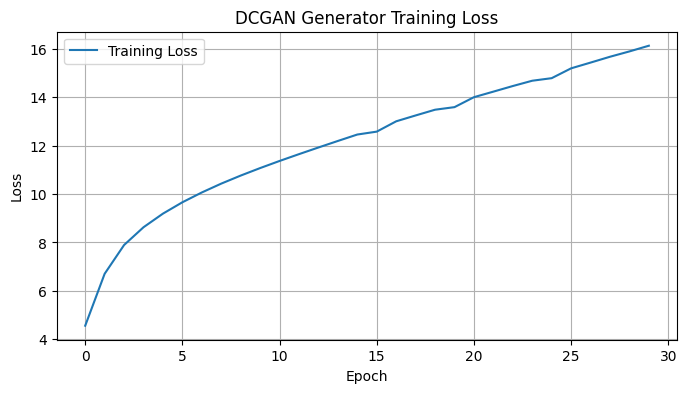

In [34]:

dcgan_gen = DCGANGenerator().to(device)
dcgan_disc = DCGANDiscriminator().to(device)

opt_g_dc = torch.optim.Adam(dcgan_gen.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_d_dc = torch.optim.Adam(dcgan_disc.parameters(), lr=2e-4, betas=(0.5, 0.999))
criterion_dcgan = nn.BCELoss()

dcgan_loader = DataLoader(TensorDataset(x_train), batch_size=128, shuffle=True)
dcgan_losses = []
epochs_dcgan = 30
start_train_dc = time.time()

dcgan_gen.train()
dcgan_disc.train()

for epoch in range(epochs_dcgan):
    epoch_loss_g = 0
    for batch in dcgan_loader:
        real = batch[0].to(device)
        batch_size = real.size(0)

        # Train Discriminator
        opt_d_dc.zero_grad()
        z = torch.randn(batch_size, 100).to(device)
        fake = dcgan_gen(z)

        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        d_loss = criterion_dcgan(dcgan_disc(real), real_labels) + criterion_dcgan(dcgan_disc(fake.detach()), fake_labels)
        d_loss.backward()
        opt_d_dc.step()

        # Train Generator
        opt_g_dc.zero_grad()
        g_loss = criterion_dcgan(dcgan_disc(fake), real_labels)
        g_loss.backward()
        opt_g_dc.step()
        epoch_loss_g += g_loss.item()

    avg_loss_g = epoch_loss_g / len(dcgan_loader)
    dcgan_losses.append(avg_loss_g)
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{epochs_dcgan}] Generator Loss: {avg_loss_g:.6f}")

time_per_epoch_dcgan = (time.time() - start_train_dc) / epochs_dcgan
latency_dcgan = measure_latency(dcgan_gen, (64, 100), is_gan=True)

# Evaluate FID Score
dcgan_gen.eval()
with torch.no_grad():
    z_eval = torch.randn(len(x_test), 100).to(device)
    dcgan_fake_images = dcgan_gen(z_eval)

dcgan_acts = get_latent_activations(dcgan_fake_images)
dcgan_fid = calculate_fid(real_acts, dcgan_acts)

print("-" * 40)
print(f"DCGAN - Time/Epoch: {time_per_epoch_dcgan:.2f}s")
print(f"DCGAN - Latency (batch 64): {latency_dcgan:.2f}ms")
print(f"DCGAN - FID Score: {dcgan_fid:.4f}")
print("-" * 40)

plot_training_graph(dcgan_losses, "DCGAN Generator Training Loss")

#### 4. Denoising Diffusion (Latent 28x28)

In [35]:
class SimpleDiffusionUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.time_embed = nn.Sequential(nn.Linear(1, 64), nn.ReLU())
        self.conv1 = nn.Sequential(nn.Conv2d(1, 64, 3, padding=1), nn.ReLU())
        self.conv2 = nn.Sequential(nn.Conv2d(64, 64, 3, padding=1), nn.ReLU())
        self.conv3 = nn.Conv2d(64, 1, 3, padding=1)

    def forward(self, x, t=None):
        # For measure_latency compatibility
        if t is None:
            t = torch.zeros(x.size(0), device=x.device)

        t = t.view(-1, 1).float() / 100.0 # Normalize t
        t_emb = self.time_embed(t).view(-1, 64, 1, 1)

        x = self.conv1(x)
        x = x + t_emb # Inject time
        x = self.conv2(x)
        return self.conv3(x)


Epoch [1/30] Loss: 0.313921
Epoch [5/30] Loss: 0.195526
Epoch [10/30] Loss: 0.184803
Epoch [15/30] Loss: 0.180105
Epoch [20/30] Loss: 0.179251
Epoch [25/30] Loss: 0.176611
Epoch [30/30] Loss: 0.175971


/tmp/ipykernel_475/2798934102.py:17: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = scipy.linalg.sqrtm(sigma1.dot(sigma2), disp=False)


----------------------------------------
Diffusion - Time/Epoch: 4.85s
Diffusion - Latency (batch 64): 0.60ms
Diffusion - FID Score: 239.9666
----------------------------------------


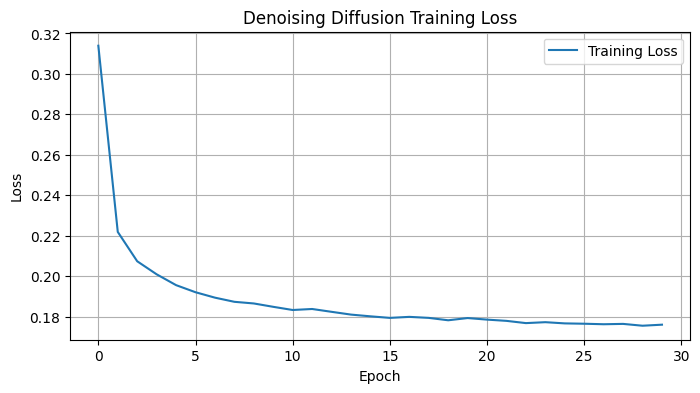

In [36]:

diffusion_model = SimpleDiffusionUNet().to(device)
optimizer_diff = torch.optim.Adam(diffusion_model.parameters(), lr=1e-3)
criterion_diff = nn.MSELoss()

# Diffusion Noise Schedule
T = 100
betas = torch.linspace(1e-4, 0.02, T).to(device)
alphas = 1. - betas
alphas_cumprod = torch.cumprod(alphas, dim=0).to(device)

diffusion_loader = DataLoader(TensorDataset(x_train), batch_size=128, shuffle=True)
diffusion_losses = []
epochs_diffusion = 30
start_train_diff = time.time()

diffusion_model.train()
for epoch in range(epochs_diffusion):
    epoch_loss = 0
    for batch in diffusion_loader:
        x0 = batch[0].view(-1, 1, 28, 28).to(device)
        batch_size = x0.size(0)

        # Sample random t for each image
        t = torch.randint(0, T, (batch_size,), device=device).long()
        noise = torch.randn_like(x0)

        # Forward process: Add noise to x0
        a_cp = alphas_cumprod[t].view(-1, 1, 1, 1)
        xt = torch.sqrt(a_cp) * x0 + torch.sqrt(1 - a_cp) * noise

        # Predict noise
        optimizer_diff.zero_grad()
        pred_noise = diffusion_model(xt, t)
        loss = criterion_diff(pred_noise, noise)
        loss.backward()
        optimizer_diff.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(diffusion_loader)
    diffusion_losses.append(avg_loss)
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{epochs_diffusion}] Loss: {avg_loss:.6f}")

time_per_epoch_diff = (time.time() - start_train_diff) / epochs_diffusion
latency_diffusion = measure_latency(diffusion_model, (64, 1, 28, 28), is_gan=True)

# Evaluate FID Score (Sampling via Reverse Process)
diffusion_model.eval()
with torch.no_grad():
    x_gen = torch.randn(len(x_test), 1, 28, 28).to(device)
    for i in reversed(range(T)):
        t_tensor = torch.full((len(x_test),), i, device=device, dtype=torch.long)
        pred_noise = diffusion_model(x_gen, t_tensor)

        alpha_t = alphas[i]
        alpha_cp_t = alphas_cumprod[i]

        if i > 0:
            z = torch.randn_like(x_gen)
        else:
            z = torch.zeros_like(x_gen)

        x_gen = (1 / torch.sqrt(alpha_t)) * (x_gen - ((1 - alpha_t) / torch.sqrt(1 - alpha_cp_t)) * pred_noise) + torch.sqrt(betas[i]) * z

    x_gen = torch.clamp(x_gen, 0.0, 1.0)

diff_acts = get_latent_activations(x_gen)
diff_fid = calculate_fid(real_acts, diff_acts)

print("-" * 40)
print(f"Diffusion - Time/Epoch: {time_per_epoch_diff:.2f}s")
print(f"Diffusion - Latency (batch 64): {latency_diffusion:.2f}ms")
print(f"Diffusion - FID Score: {diff_fid:.4f}")
print("-" * 40)

plot_training_graph(diffusion_losses, "Denoising Diffusion Training Loss")

## Comprehensive Model Summary
Compiling all the tracked metrics across Autoencoders and Generative Models into a single table.

In [37]:
import pandas as pd

# Measure missing latencies for models trained earlier
latency_ae = measure_latency(autoencoder, (64, 784))
latency_vae = measure_latency(vae_model, (64, 784))

summary_data = {
    "Vanilla Autoencoder": {
        "Time/Epoch (s)": time_per_epoch_ae,
        "Latency (ms/batch 64)": latency_ae,
        "Test MSE": ae_metrics["MSE"],
        "Test PSNR (dB)": ae_metrics["PSNR"],
        "FID Score": ae_fid
    },
    "Variational Autoencoder (VAE)": {
        "Time/Epoch (s)": time_per_epoch_vae,
        "Latency (ms/batch 64)": latency_vae,
        "Test MSE": vae_metrics["MSE"],
        "Test PSNR (dB)": vae_metrics["PSNR"],
        "FID Score": vae_fid
    },
    "Sparse Autoencoder": {
        "Time/Epoch (s)": time_per_epoch_sae,
        "Latency (ms/batch 64)": latency_sae,
        "Test MSE": sae_test_mse,
        "Test PSNR (dB)": sae_test_psnr,
        "FID Score": "N/A"
    },
    "GAN": {
        "Time/Epoch (s)": time_per_epoch_gan,
        "Latency (ms/batch 64)": latency_gan,
        "Test MSE": "N/A",
        "Test PSNR (dB)": "N/A",
        "FID Score": gan_fid
    },
    "DCGAN": {
        "Time/Epoch (s)": time_per_epoch_dcgan,
        "Latency (ms/batch 64)": latency_dcgan,
        "Test MSE": "N/A",
        "Test PSNR (dB)": "N/A",
        "FID Score": dcgan_fid
    },
    "Denoising Diffusion": {
        "Time/Epoch (s)": time_per_epoch_diff,
        "Latency (ms/batch 64)": latency_diffusion,
        "Test MSE": "N/A",
        "Test PSNR (dB)": "N/A",
        "FID Score": diff_fid
    }
}

summary_df = pd.DataFrame(summary_data).T
summary_df.index.name = "Model"

print("Comprehensive Model Comparison:")
display(summary_df)

Comprehensive Model Comparison:


,Time/Epoch (s),Latency (ms/batch 64),Test MSE,Test PSNR (dB),FID Score
Model,,,,,
Vanilla Autoencoder,1.134858,0.90003,0.468682,3.403299,73.075443
Variational Autoencoder (VAE),1.503869,0.724554,0.50386,3.081931,87.46415
Sparse Autoencoder,1.326218,0.32568,0.853749,0.85251,N/A
GAN,2.618898,0.241756,N/A,N/A,532.085709
DCGAN,28.891506,0.442028,N/A,N/A,459.271105
Denoising Diffusion,4.84697,0.6001,N/A,N/A,239.966575


In [38]:
# Update Summary Table with the newly calculated metrics
summary_data['Vanilla Autoencoder']['Time/Epoch (s)'] = time_per_epoch_ae
summary_data['Vanilla Autoencoder']['Latency (ms/batch 64)'] = latency_ae
summary_data['Variational Autoencoder (VAE)']['Time/Epoch (s)'] = time_per_epoch_vae
summary_data['Variational Autoencoder (VAE)']['Latency (ms/batch 64)'] = latency_vae
summary_data['Variational Autoencoder (VAE)']['FID Score'] = vae_fid

summary_df = pd.DataFrame(summary_data).T
summary_df.index.name = "Model"

print("Updated Comprehensive Model Comparison:")
display(summary_df)

Updated Comprehensive Model Comparison:


,Time/Epoch (s),Latency (ms/batch 64),Test MSE,Test PSNR (dB),FID Score
Model,,,,,
Vanilla Autoencoder,1.134858,0.90003,0.468682,3.403299,73.075443
Variational Autoencoder (VAE),1.503869,0.724554,0.50386,3.081931,87.46415
Sparse Autoencoder,1.326218,0.32568,0.853749,0.85251,N/A
GAN,2.618898,0.241756,N/A,N/A,532.085709
DCGAN,28.891506,0.442028,N/A,N/A,459.271105
Denoising Diffusion,4.84697,0.6001,N/A,N/A,239.966575


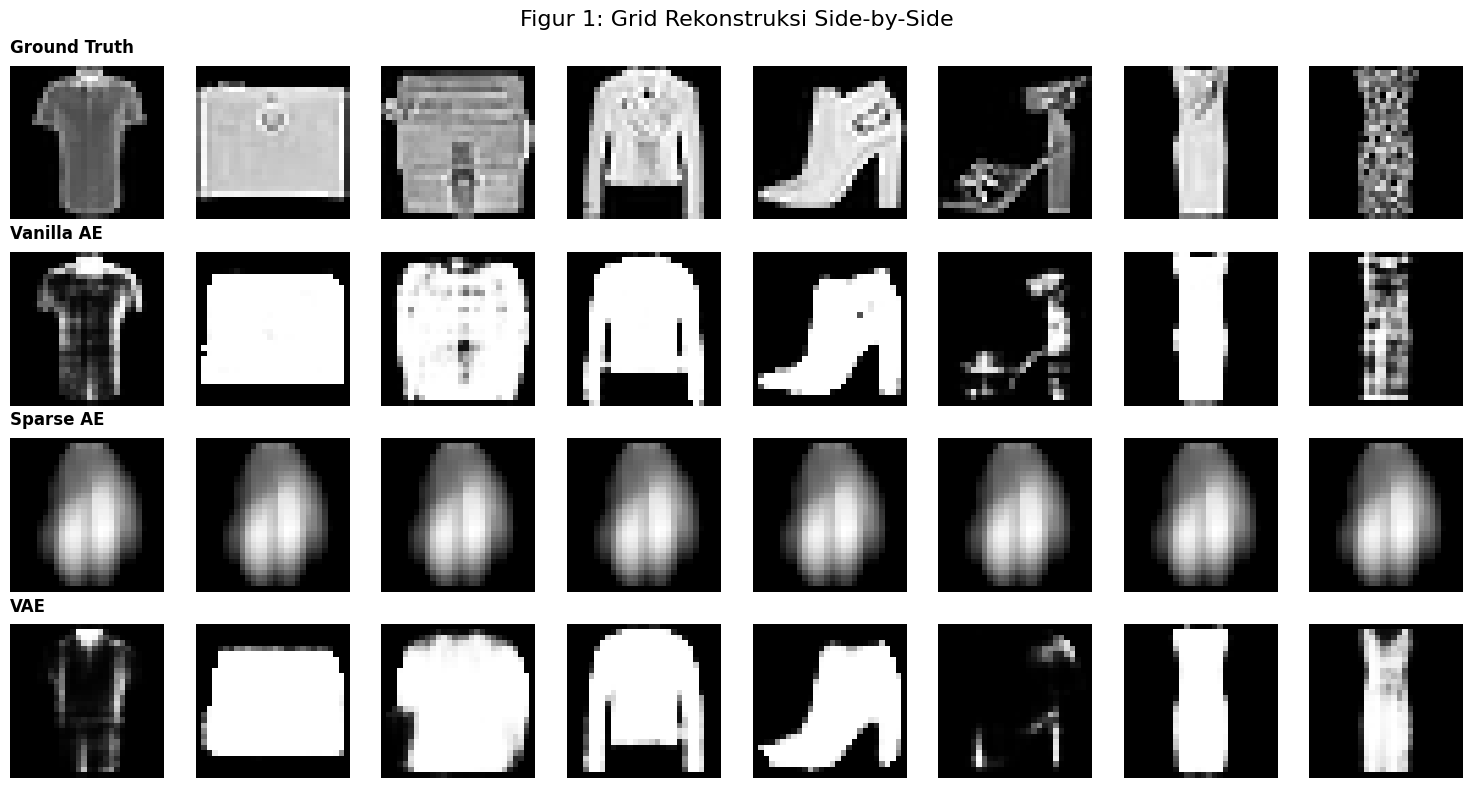

In [39]:


num_samples = 8
indices = np.random.choice(len(x_test), num_samples, replace=False)
test_images = x_test[indices].to(device)

with torch.no_grad():
    ae_recon = autoencoder(test_images).cpu()
    sae_recon, _ = sparse_ae(test_images)
    sae_recon = sae_recon.cpu()
    vae_recon, _, _ = vae_model(test_images)
    vae_recon = vae_recon.cpu()

orig_images = test_images.cpu().numpy()

fig, axes = plt.subplots(4, num_samples, figsize=(15, 8))
titles = ['Ground Truth', 'Vanilla AE', 'Sparse AE', 'VAE']
images_list = [orig_images, ae_recon.numpy(), sae_recon.numpy(), vae_recon.numpy()]

for row in range(4):
    for col in range(num_samples):
        ax = axes[row, col]
        ax.imshow(images_list[row][col].reshape(28, 28), cmap='gray')
        ax.axis('off')
        if col == 0:
            ax.set_title(titles[row], loc='left', pad=10, weight='bold')

plt.suptitle('Figur 1: Grid Rekonstruksi Side-by-Side', fontsize=16)
plt.tight_layout()
plt.savefig('figur_1.png')
plt.show()

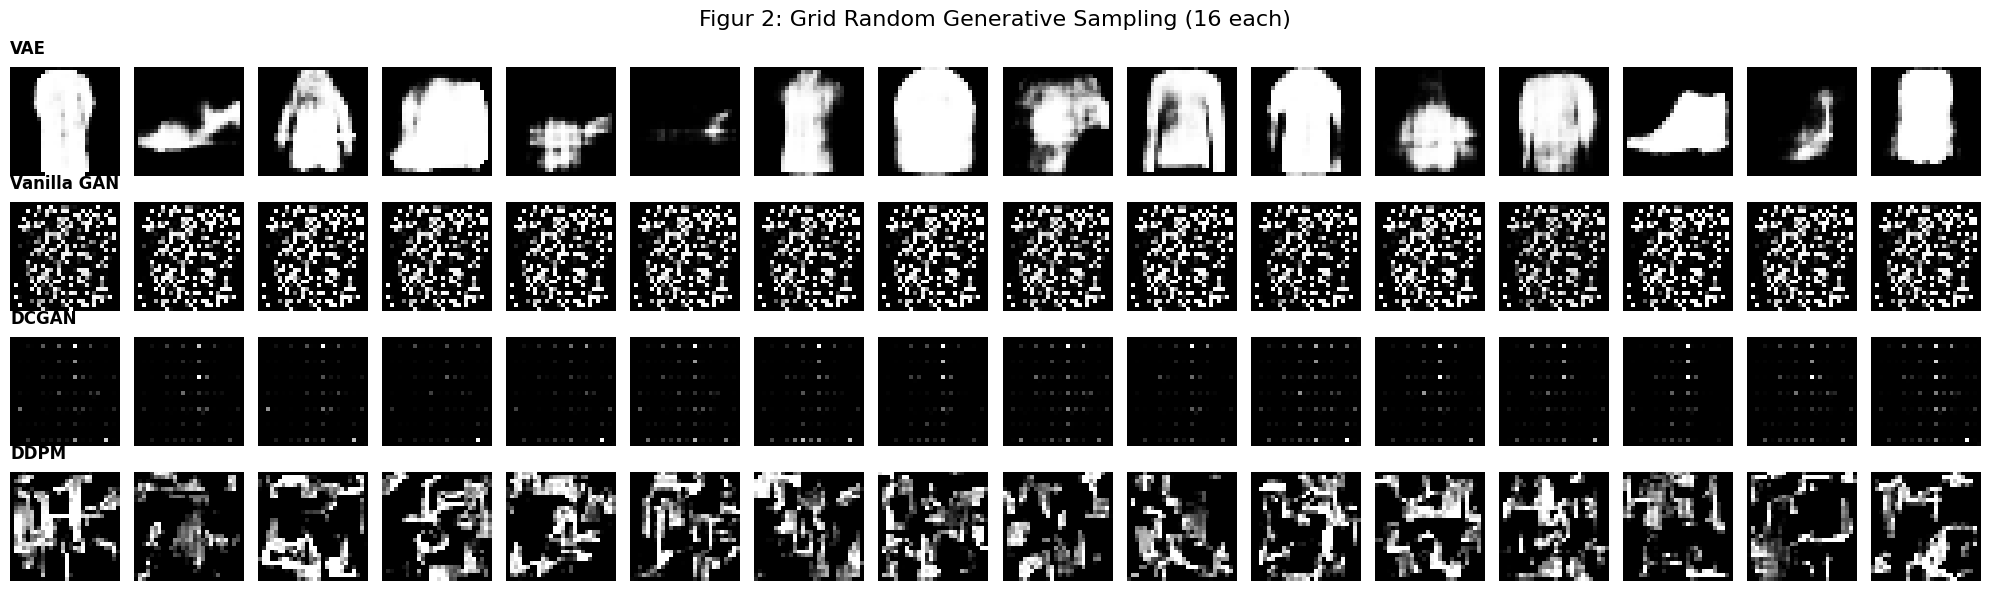

In [40]:
num_gen = 16

with torch.no_grad():
    z_vae = torch.randn(num_gen, 64).to(device)
    vae_samples = vae_model.decoder(z_vae).cpu().numpy()

    z_gan = torch.randn(num_gen, 100).to(device)
    gan_samples = gan_gen(z_gan).cpu().numpy()

    z_dcgan = torch.randn(num_gen, 100).to(device)
    dcgan_samples = dcgan_gen(z_dcgan).cpu().numpy()

    x_t = torch.randn(num_gen, 1, 28, 28).to(device)
    for i in reversed(range(100)):
        t_tensor = torch.full((num_gen,), i, device=device, dtype=torch.long)
        pred_noise = diffusion_model(x_t, t_tensor)
        alpha_t = alphas[i]
        alpha_cp_t = alphas_cumprod[i]
        z = torch.randn_like(x_t) if i > 0 else torch.zeros_like(x_t)
        x_t = (1 / torch.sqrt(alpha_t)) * (x_t - ((1 - alpha_t) / torch.sqrt(1 - alpha_cp_t)) * pred_noise) + torch.sqrt(betas[i]) * z
    ddpm_samples = torch.clamp(x_t, 0.0, 1.0).cpu().numpy()

fig, axes = plt.subplots(4, 16, figsize=(20, 6))
model_samples = [vae_samples, gan_samples, dcgan_samples, ddpm_samples]
model_names = ['VAE', 'Vanilla GAN', 'DCGAN', 'DDPM']

for row, (samples, name) in enumerate(zip(model_samples, model_names)):
    for col in range(16):
        ax = axes[row, col]
        ax.imshow(samples[col].reshape(28, 28), cmap='gray')
        ax.axis('off')
        if col == 0:
            ax.set_title(name, loc='left', pad=10, weight='bold')

plt.suptitle('Figur 2: Grid Random Generative Sampling (16 each)', fontsize=16)
plt.tight_layout()
plt.savefig('figur_2.png')
plt.show()

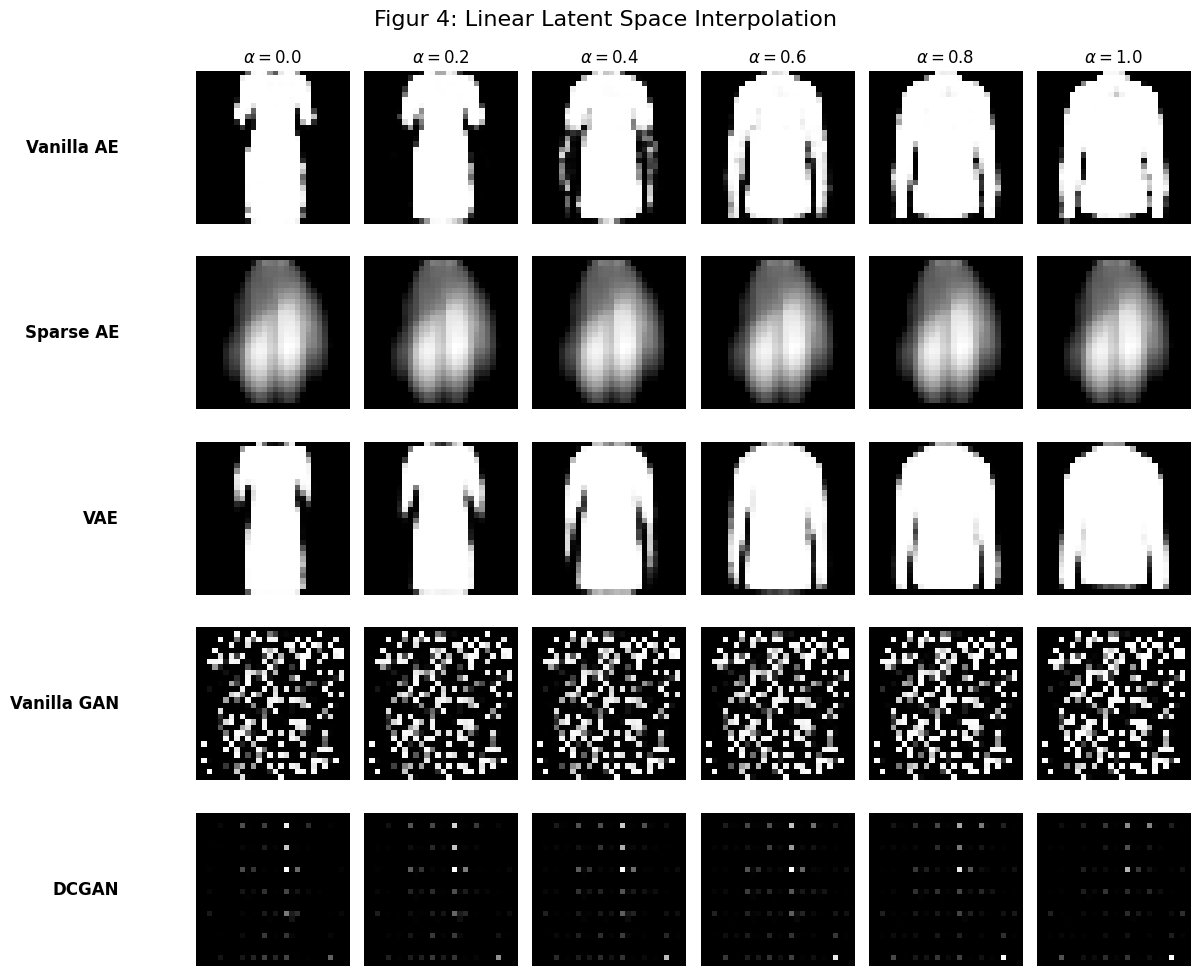

In [41]:
alphas_interp = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

idx_A, idx_B = 0, 100

# VAE, AE, SAE latent vectors
with torch.no_grad():
    xA, xB = x_test[idx_A].to(device), x_test[idx_B].to(device)
    zA_ae = autoencoder.encoder(xA); zB_ae = autoencoder.encoder(xB)
    zA_sae = sparse_ae.encoder(xA); zB_sae = sparse_ae.encoder(xB)
    _, zA_vae, _ = vae_model.forward(xA); _, zB_vae, _ = vae_model.forward(xB)

# GAN & DCGAN latent vectors (Random)
zA_gan = torch.randn(1, 100).to(device); zB_gan = torch.randn(1, 100).to(device)

fig, axes = plt.subplots(5, 6, figsize=(12, 10))
models = ['Vanilla AE', 'Sparse AE', 'VAE', 'Vanilla GAN', 'DCGAN']

for col, alpha in enumerate(alphas_interp):
    with torch.no_grad():
        # AE
        z_ae = (1 - alpha) * zA_ae + alpha * zB_ae
        img_ae = autoencoder.decoder(z_ae).cpu().numpy()

        # SAE
        z_sae = (1 - alpha) * zA_sae + alpha * zB_sae
        img_sae = sparse_ae.decoder(z_sae).cpu().numpy()

        # VAE
        z_vae = (1 - alpha) * zA_vae + alpha * zB_vae
        img_vae = vae_model.decoder(z_vae).cpu().numpy()

        # GAN
        z_gan = (1 - alpha) * zA_gan + alpha * zB_gan
        img_gan = gan_gen(z_gan).cpu().numpy()

        # DCGAN
        img_dcgan = dcgan_gen(z_gan).cpu().numpy()

    images = [img_ae, img_sae, img_vae, img_gan, img_dcgan]

    for row, (img, name) in enumerate(zip(images, models)):
        ax = axes[row, col]
        ax.imshow(img.reshape(28, 28), cmap='gray')
        ax.axis('off')
        if row == 0:
            ax.set_title(rf'$\alpha={alpha}$', fontsize=12)
        if col == 0:
            ax.text(-0.5, 0.5, name, transform=ax.transAxes, fontsize=12, va='center', ha='right', weight='bold')

plt.suptitle('Figur 4: Linear Latent Space Interpolation', fontsize=16)
plt.tight_layout()
plt.savefig('figur_4.png')
plt.show()

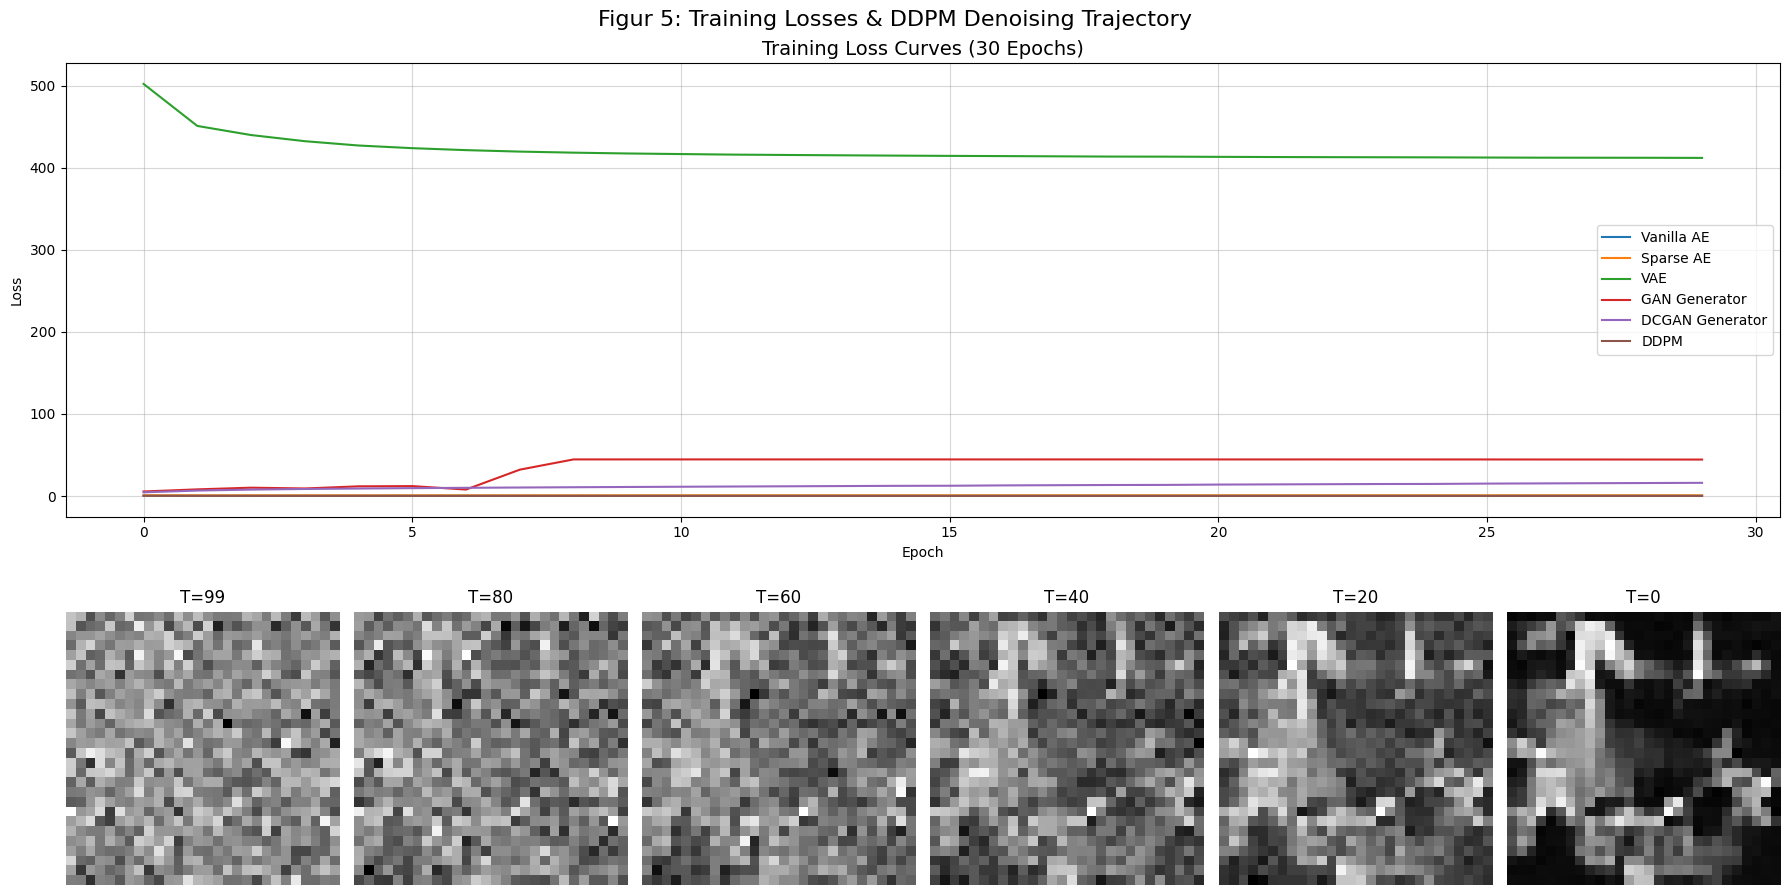

In [42]:
fig = plt.figure(figsize=(18, 10))

ax1 = plt.subplot2grid((2, 2), (0, 0), colspan=2)
ax1.plot(ae_losses, label='Vanilla AE')
ax1.plot(sae_losses, label='Sparse AE')
ax1.plot(vae_losses, label='VAE')
ax1.plot(gan_losses, label='GAN Generator')
ax1.plot(dcgan_losses, label='DCGAN Generator')
ax1.plot(diffusion_losses, label='DDPM')
ax1.set_title('Training Loss Curves (30 Epochs)', fontsize=14)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, alpha=0.5)

steps_to_show = [99, 80, 60, 40, 20, 0]

with torch.no_grad():
    x_t = torch.randn(1, 1, 28, 28).to(device)
    trajectory = []
    for i in reversed(range(100)):
        if i in steps_to_show:
            trajectory.append((i, x_t.cpu().numpy()))

        t_tensor = torch.full((1,), i, device=device, dtype=torch.long)
        pred_noise = diffusion_model(x_t, t_tensor)
        alpha_t = alphas[i]
        alpha_cp_t = alphas_cumprod[i]
        z = torch.randn_like(x_t) if i > 0 else torch.zeros_like(x_t)
        x_t = (1 / torch.sqrt(alpha_t)) * (x_t - ((1 - alpha_t) / torch.sqrt(1 - alpha_cp_t)) * pred_noise) + torch.sqrt(betas[i]) * z

    trajectory.append((0, torch.clamp(x_t, 0.0, 1.0).cpu().numpy()))

ax2_axes = [plt.subplot2grid((2, 6), (1, i)) for i in range(6)]
for idx, (step, img) in enumerate(trajectory[:6]):
    ax2_axes[idx].imshow(img.reshape(28, 28), cmap='gray')
    ax2_axes[idx].set_title(f'T={step}')
    ax2_axes[idx].axis('off')

plt.suptitle('Figur 5: Training Losses & DDPM Denoising Trajectory', fontsize=16)
plt.tight_layout()
plt.savefig('figur_5.png')
plt.show()